[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_top.ipynb)


# Symmetric top under gravity

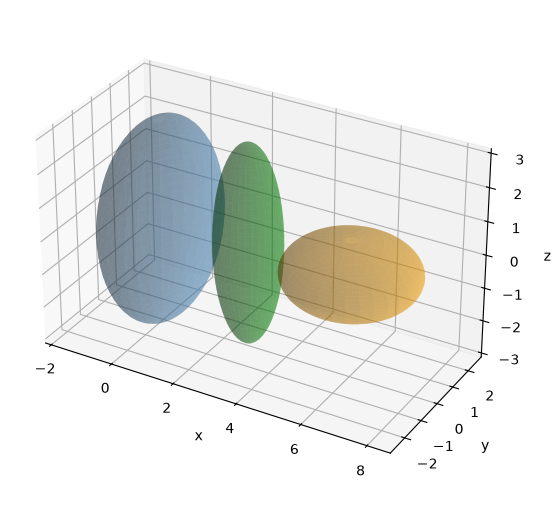

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.integrate import solve_ivp
def ellipsoid(ax,radii,centre=(0,0,0),color='steelblue',alpha=.35):
    u,v=np.meshgrid(np.linspace(0,2*np.pi,65),np.linspace(0,np.pi,35))
    xyz=[centre[0]+radii[0]*np.sin(v)*np.cos(u),centre[1]+radii[1]*np.sin(v)*np.sin(u),centre[2]+radii[2]*np.cos(v)]
    ax.plot_surface(*xyz,color=color,alpha=alpha,linewidth=0)
def axes3d(fig):
    ax=fig.add_subplot(projection='3d'); ax.set(xlabel='x',ylabel='y',zlabel='z'); ax.set_box_aspect((1,1,1)); return ax
def Rz(q): return sp.Matrix([[sp.cos(q),-sp.sin(q),0],[sp.sin(q),sp.cos(q),0],[0,0,1]])
def Rx(q): return sp.Matrix([[1,0,0],[0,sp.cos(q),-sp.sin(q)],[0,sp.sin(q),sp.cos(q)]])
fig=plt.figure(figsize=(9,5),layout='constrained'); ax=axes3d(fig)
for radii,centre,color in [((1.5,2.5,3),(0,0,0),'steelblue'),((2,2,1),(6,0,0),'orange'),((1,1,3),(2.8,0,0),'green')]:
    ellipsoid(ax,radii,centre,color)
ax.set_box_aspect((10,5,6)); plt.show()

## Equilateral triangle

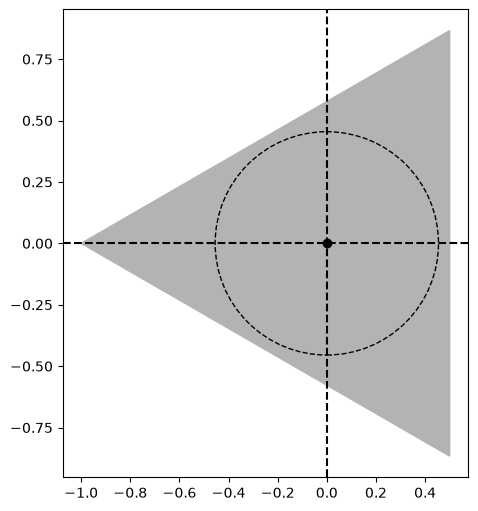

In [2]:
angles=np.arange(3)*2*np.pi/3+np.pi/3
triangle=np.array([np.cos(angles),np.sin(angles)]).T
fig,ax=plt.subplots(figsize=(5,5),layout='constrained'); ax.fill(*triangle.T,color='.7')
ax.plot(0,0,'ko'); ax.axhline(0,ls='--',color='black'); ax.axvline(0,ls='--',color='black')
ax.add_patch(plt.Circle((0,0),1/2.2,fill=False,ls='--')); ax.set(aspect='equal'); plt.show()

$$
{I}_{1}=2\rho {\int }_{0}^{\frac{x}{\sqrt{3}}}{\int }_{0}^{\frac{\sqrt{3}}{2}}{y}^{2}dxdy=\frac{\rho }{32} \frac{{a}^{4}}{\sqrt{3}}={I}_{2}=m \frac{{a}^{2}}{24} \Rightarrow {I}_{3}=m \frac{{a}^{2}}{12}
$$

In [3]:
x,y=sp.symbols('x y',real=True)
a=sp.symbols('a',positive=True)
i12=2*sp.integrate(sp.integrate(y**2,(y,0,x/sp.sqrt(3))),(x,0,a*sp.sqrt(3)/2))
area=a**2*sp.sqrt(3)/4
display(i12,sp.simplify(i12/area))

sqrt(3)*a**4/96

a**2/24

Alternatively, calculate $I_3$ by integrating over a family of similar triangles:

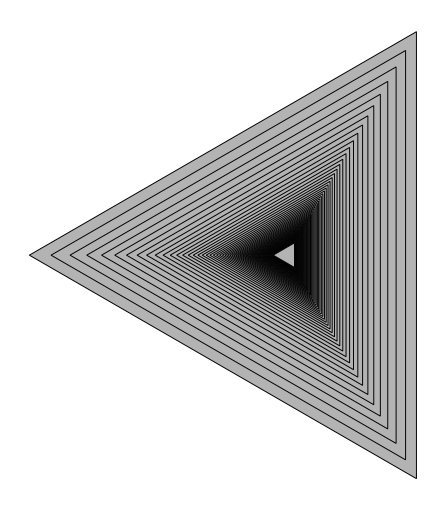

In [4]:
fig,ax=plt.subplots(figsize=(5,5),layout='constrained')
for scale in 1/np.arange(1,5.001,.05)**1.8:
    ax.fill(*(scale*triangle).T,facecolor='.7',edgecolor='black',lw=.7)
ax.set(aspect='equal'); ax.axis('off'); plt.show()

$$
{I}_{3}=3\rho \int dI={\int }_{0}^{\frac{a}{2\sqrt{3}}}\left(\frac{{l}^{2}}{12}+{x}^{2}\right)l dx, x=\frac{l}{2\sqrt{3}}
$$

In [5]:
i3=3*sp.integrate((y**2/12+(y/(2*sp.sqrt(3)))**2)*y/(2*sp.sqrt(3)),(y,0,a))/area
display(sp.simplify(i3))

a**2/12

## Example: Cube

A homogeneous cube is a spherical top.

$$
{I}_{3}=\rho {\int }_{-a/2}^{a/2}{\int }_{-a/2}^{a/2}{\int }_{-a/2}^{a/2}\left({x}^{2}+{y}^{2}\right)dxdydz=\frac{\rho }{3} \frac{{a}^{5}}{2}={I}_{1}={I}_{2}=\frac{M {a}^{2}}{6}\\
$$

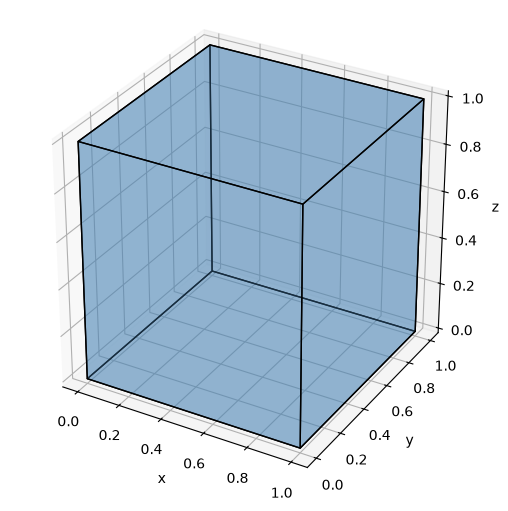

In [6]:
from itertools import product,combinations
vertices=np.array(list(product([0,1],repeat=3)))
fig=plt.figure(figsize=(5,5),layout='constrained'); ax=axes3d(fig)
faces=[]
for dim in range(3):
    for side in (0,1):
        face=vertices[vertices[:,dim]==side][[0,1,3,2]]; faces.append(face)
ax.add_collection3d(Poly3DCollection(faces,facecolor='steelblue',edgecolor='black',alpha=.35)); ax.auto_scale_xyz([0,1],[0,1],[0,1]); plt.show()

## Example: Regular tetrahedron

Divide the tetrahedron into equilateral triangular layers and use the preceding result.

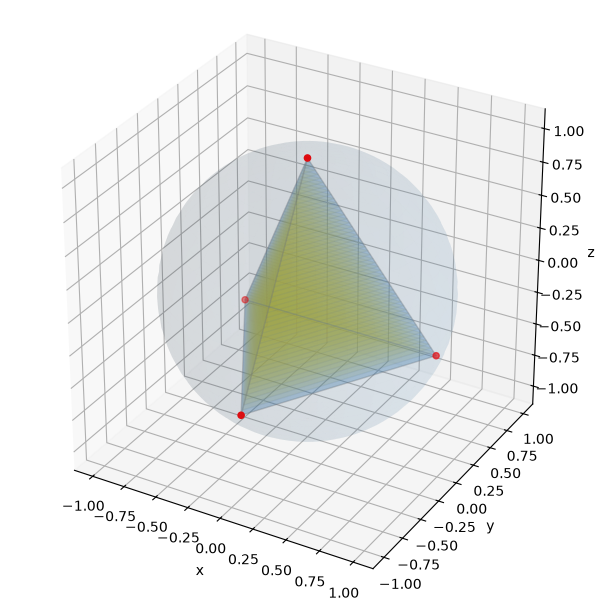

In [7]:
p0=sp.Matrix([0,0,1]); p1=Rx(2*sp.pi/3)*p0; p2=Rz(2*sp.pi/3)*p1; p3=Rz(2*sp.pi/3)*p2
p=np.array([list(v) for v in [p0,p1,p2,p3]],dtype=float)
fig=plt.figure(figsize=(6,6),layout='constrained'); ax=axes3d(fig)
faces=[p[list(face)] for face in combinations(range(4),3)]
ax.add_collection3d(Poly3DCollection(faces,alpha=.2,facecolor='steelblue',edgecolor='gray'))
layers=[p[0]+(p[1:]-p[0])*fraction/50 for fraction in range(1,50)]
ax.add_collection3d(Poly3DCollection(layers,alpha=.12,edgecolor='gray',facecolor='gold'))
ellipsoid(ax,(1,1,1),alpha=.08); ax.scatter(*p.T,color='red'); plt.show()
# These original illustration vertices are not a regular tetrahedron.

$$
{I}_{3}=\int dI=\int \frac{{l}^{2}}{12}dm={\int }_{0}^{a\sqrt{\frac{2}{3}}}\sqrt{3}\frac{{l}^{2}}{4}\frac{{l}^{2}}{12} dh, \\ h=l\sqrt{\frac{2}{3}},m=\rho  {a}^{3}\frac{\sqrt{2}}{12}
$$

In [8]:
display(sp.simplify(sp.integrate(x**2/12*x**2*sp.sqrt(3)/4*sp.sqrt(2)/sp.sqrt(3),(x,0,a))/(sp.sqrt(2)*a**3/12)))

a**2/20

$$
{I}_{1}={I}_{2}={I}_{3}=m \frac{{a}^{2}}{20}
$$

## Kinematics of rotation. Euler’s angles

To describe the rotation of a rigid body we need to describe the change of its orientation with help of some appropriate angles. One of the most common way is to use Euler’s angles.


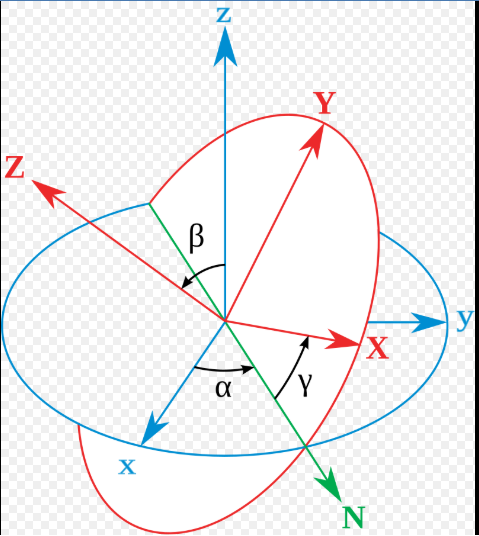


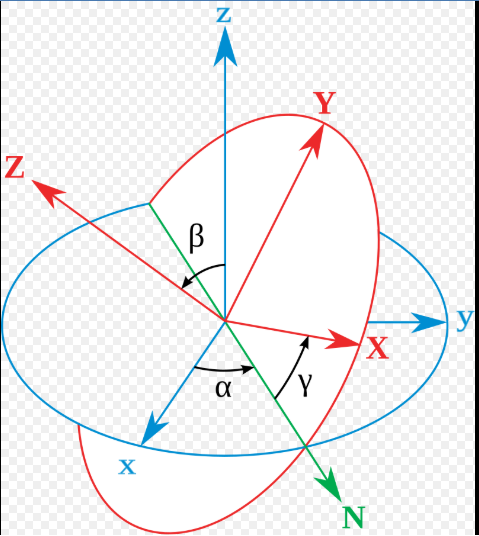

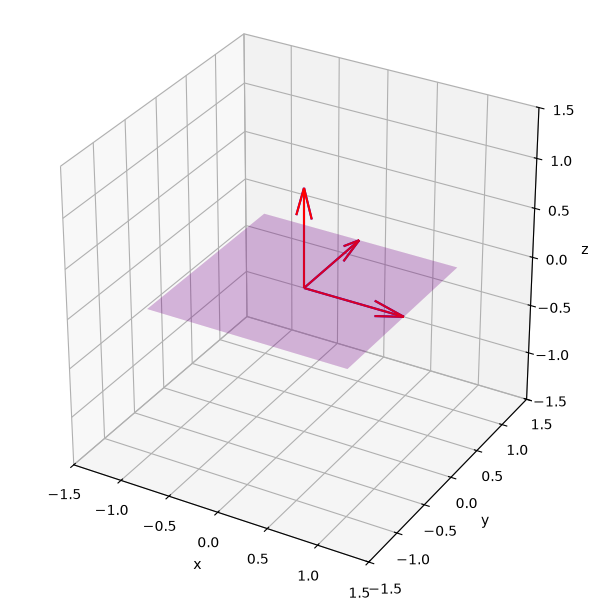

interactive(children=(FloatSlider(value=0.0, description='b', max=3.141592653589793, min=-3.141592653589793, s…

In [9]:
from scipy.spatial.transform import Rotation
def show_axis_rotation(b=0.,a1=0.,a2=0.):
    axis=np.array([np.sin(a1)*np.cos(a2),np.sin(a1)*np.sin(a2),np.cos(a1)])
    R=Rotation.from_rotvec(b*axis).as_matrix()
    fig=plt.figure(figsize=(7,6),layout='constrained'); ax=axes3d(fig)
    for v in np.eye(3):
        ax.quiver(0,0,0,*v,color='blue'); ax.quiver(0,0,0,*(R@v),color='red')
    plane=np.array([[-1,-1,0],[1,-1,0],[1,1,0],[-1,1,0]])
    ax.add_collection3d(Poly3DCollection([plane],facecolor='red',alpha=.15))
    ax.add_collection3d(Poly3DCollection([plane@R.T],facecolor='blue',alpha=.15))
    node=np.sqrt(2.3)*np.cross([0,0,1],R[:,2]); ax.plot(*np.array([-node,node]).T,'k--')
    ax.set(xlim=(-1.5,1.5),ylim=(-1.5,1.5),zlim=(-1.5,1.5)); plt.show()
show_axis_rotation()
axis_controls=widgets.interactive(show_axis_rotation,**{name:widgets.FloatSlider(min=-np.pi,max=np.pi,value=0,step=.05) for name in ('b','a1','a2')})
display(axis_controls)

Any rotation can be expressed as a composition of three Euler rotations. The corresponding rotation matrix is

In [10]:
a1,a2,a3=sp.symbols('alpha_1 alpha_2 alpha_3',real=True)
eulermtrx=Rz(a3)*Rx(a2)*Rz(a1)
display(eulermtrx,sp.trigsimp(eulermtrx.T*eulermtrx)==sp.eye(3))

Matrix([
[-sin(alpha_1)*sin(alpha_3)*cos(alpha_2) + cos(alpha_1)*cos(alpha_3), -sin(alpha_1)*cos(alpha_3) - sin(alpha_3)*cos(alpha_1)*cos(alpha_2),  sin(alpha_2)*sin(alpha_3)],
[ sin(alpha_1)*cos(alpha_2)*cos(alpha_3) + sin(alpha_3)*cos(alpha_1), -sin(alpha_1)*sin(alpha_3) + cos(alpha_1)*cos(alpha_2)*cos(alpha_3), -sin(alpha_2)*cos(alpha_3)],
[                                          sin(alpha_1)*sin(alpha_2),                                           sin(alpha_2)*cos(alpha_1),               cos(alpha_2)]])

True

The angular velocity vector can be constructed as a sum of these rotation components

$$
\mathbf{\omega } = \dot{\alpha } \mathbf{k}\mathbf{+}\dot{\beta } {\mathbf{e}}_{N}+\dot{\gamma } {\mathbf{e}}_{3}\\ \mathbf{\Omega }\mathbf{ }\mathbf{=}\left(\dot{\alpha }\sin{\gamma}  \sin{\beta} +\dot{\beta }\cos{\gamma} \right){\mathbf{e}}_{1}+\left(\dot{\alpha }\cos{\gamma}  \sin{\beta} -\dot{\beta }\sin{\gamma} \right){\mathbf{e}}_{2}+\mathbf{ }\left(\dot{\alpha } \cos{\beta} +\dot{\gamma }\right){\mathbf{e}}_{3}
$$

## Free rotation

The Lagrange function of a free rotating (around center of inertia) body is 

$$
L=\frac{1}{2}\sum {I}_{ij}{\omega }_{i}{\omega }_{j}
$$

The EoM are

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  {\omega }_{i} }\right)-\frac{\partial L}{\partial  {q}_{i} }=\frac{d}{dt}\left(\sum {I}_{ij}{\omega }_{j}\right)=0
$$

so it is natural consequence of inertia that the angular  momentum is conserved:

$$
\frac{d \mathbf{L}}{dt}=0
$$

Conserved angular momentum does not imply constant angular velocity. Steady free rotation occurs along a principal axis, reflecting the tensor character of rotational inertia.

$$
\frac{d \mathbf{p}}{dt}=0\Rightarrow \frac{d\mathbf{v}}{dt}=0
$$

Angular momentum vector $M={R}^{-1}\mathbf{L}$  in fixed-body frame therefore moves so that 

$$
0=\frac{d \mathbf{L}}{dt}=\frac{dR}{dt}\mathbf{M}+R \frac{d\mathbf{M}}{dt}=R\left({R}^{-1}\frac{dR}{dt}\mathbf{M}+ \frac{d\mathbf{M}}{dt}\right)=R\left(\mathbf{\Omega }\times \mathbf{M}+ \frac{d \mathbf{M}}{dt}\right)\Rightarrow  \frac{d \mathbf{M}}{dt}+\mathbf{\Omega }\times \mathbf{M}=0
$$

Therefore in fixed-body system vector M moves around Ω. In terms of components of Ω

$$
{I}_{1}\frac{d {\mathbf{\Omega }}_{1}}{dt}=\left({I}_{2}-{I}_{3}\right){\Omega }_{2}{\Omega }_{3}\\ {I}_{2}\frac{d {\mathbf{\Omega }}_{2}}{dt}=\left({I}_{3}-{I}_{1}\right){\Omega }_{3}{\Omega }_{1}\\ {I}_{3}\frac{d {\mathbf{\Omega }}_{3}}{dt}=\left({I}_{1}-{I}_{2}\right){\Omega }_{1}{\Omega }_{2}
$$

Conservation of kinetic energy and angular momentum magnitude confines the tip of the body-frame angular momentum to the intersection of an ellipsoid and a sphere.

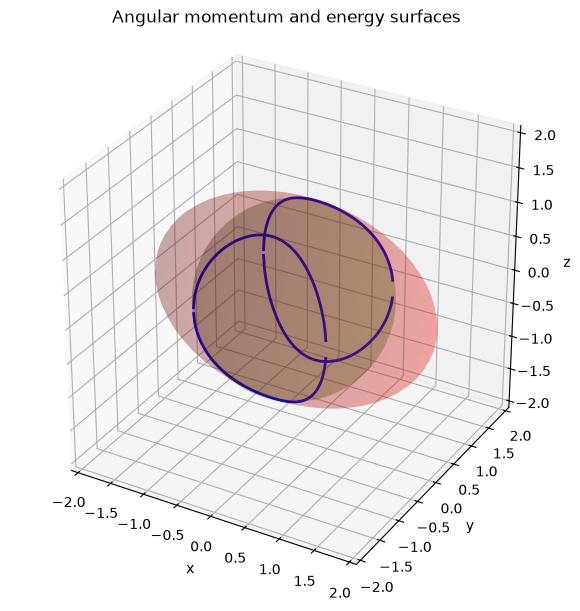

interactive(children=(FloatSlider(value=1.7, description='level', max=3.7, min=0.9, step=0.02), Output()), _do…

In [11]:
def show_invariants(level=1.7):
    fig=plt.figure(figsize=(6,6),layout='constrained'); ax=axes3d(fig)
    ellipsoid(ax,(2,1,np.sqrt(2)),color='red',alpha=.18)
    ellipsoid(ax,(np.sqrt(level),)*3,color='green',alpha=.16)
    angle=np.linspace(0,2*np.pi,3000); A=np.cos(angle)**2/4+np.sin(angle)**2
    with np.errstate(divide='ignore',invalid='ignore'):
        z2=(1-level*A)/(.5-A)
    valid=(z2>=0)&(z2<=level)
    zcoord=np.sqrt(np.where(valid,z2,np.nan)); rxy=np.sqrt(np.where(valid,level-z2,np.nan))
    for sign in (-1,1): ax.plot(rxy*np.cos(angle),rxy*np.sin(angle),sign*zcoord,color='blue',lw=2)
    ax.set(xlim=(-2.1,2.1),ylim=(-2.1,2.1),zlim=(-2.1,2.1),title='Angular momentum and energy surfaces'); plt.show()
show_invariants()
invariant_controls=widgets.interactive(show_invariants,level=widgets.FloatSlider(min=.9,max=3.7,step=.02,value=1.7))
display(invariant_controls)

Rotation around the largest and smallest principal-moment axes is stable; rotation around the intermediate axis is unstable (the tennis-racket theorem or Dzhanibekov effect).

If there is external torque T then (N is the torque vector wrt fixed-body system):

$$
\frac{d \mathbf{L}}{dt}=\mathbf{T}\mathbf{\Rightarrow }\frac{d \mathbf{M}}{dt}+\mathbf{\Omega }\times \mathbf{M}=\mathbf{N}\mathbf{,}\mathbf{ }\mathbf{T}\mathbf{=}R\mathbf{ }\mathbf{N}
$$

This is Euler’s equation of rigid body rotation

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)